 In this post, we will illustrate the common mistakes that can be made when using feature importance for
 model inspection and feature selection.

 When inspecting the behavior of a machine learning model with feature importance,
 it is important to keep in mind that the conclusions we can make will depend on the quality
 of the model. Indeed, when a model performs poorly, the resulting feature importance should
 be used to understand how to improve the model but not to draw conclusion on the underlying
 data-generating process.

 Mis-specified model
 ------------------

 We first look at how a mis-specified model, such as a linear model on a non-linear problem,
 can lead to making the wrong conclusion.

 We construct a synthetic problem for which a linear model is not able to predict better than
 the empty model, i.e., the model predicting the observed average of the target.

 As we can see, the model assigns a zero coefficient to the feature of index 1, indicating that it can learn
 nothing from it. We might want to conclude that this feature holds no information on the target.
 However, since the performance of our model is really bad on external data, we should not draw any conclusion
 on the underlying process and focus on improving the model first.

In [ ]:
import numpy as np
from sklearn.linear_model import LassoCV
from sklearn.model_selection import train_test_split

rng = np.random.RandomState(0)
n_samples = 1_000

sigma = 0.5
X = rng.choice(np.arange(-1, 2), 3 * n_samples).reshape((n_samples, 3))
y = X[:, 0] + (X[:, 0] + X[:, 1]) ** 2 + rng.normal(0, sigma**2, n_samples)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=rng
)

linear_regressor = LassoCV(random_state=rng)
linear_regressor.fit(X_train, y_train)
print("Features with non zero coef:")
print(
    [
        f"Feature {idx}, coef: {linear_regressor.coef_[idx]:.2f}"
        for idx in range(3)
        if linear_regressor.coef_[idx] != 0
    ]
)
print("Features with zero coef:")
print([f"x{idx}" for idx in range(3) if linear_regressor.coef_[idx] == 0])
print(f"Test R^2 score of the model: {linear_regressor.score(X_test, y_test):.3f}")

Features with non zero coef:
['Feature 0, coef: 0.90']
Features with zero coef:
['x1', 'x2']
Test R^2 score of the model: 0.253


 To try and improve the model, we let it consider non linear interactions between the features by
 passing them through a `PolynomialFeatures` transformer.

 We now see that $X_0$, $X_0^2$, $X_1^2$ and $X_0 X_1$ receive non zero coefficients.
 Since the $R^2$ score of the model on test data is close to one and does not drop when we train on
 half the data, we know that the model is well specified. Therefore we can draw conclusions on the
 importance of the features for the underlying process.

 Discarding $X_1$ at the previous step would have been a mistake: it is used by the properly specified
 model. It was ignored by the previous model as its impact is only through its square and an
 interaction term. We can now say that it is important for the underlying process. $X_2$
 on the contrary, despite receiving a non zero coefficient with the first model, is not used by the
 proper model: it was probably used to overfit initially but was discarded when more actually informative
 features arose.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

PF = PolynomialFeatures(degree=2)
X_poly = PF.fit_transform(X)
feature_names = PF.get_feature_names_out()
X_poly_train, X_poly_test = train_test_split(X_poly, test_size=0.2, random_state=rng)

linear_regressor.fit(X_poly_train, y_train)
print("Features with non zero coef:")
print(
    [
        f"{feature_names[idx]}, coef: {linear_regressor.coef_[idx]:.2f}"
        for idx in range(len(feature_names))
        if linear_regressor.coef_[idx] > 0.01
    ]
)
print("Features with zero coef:")
print(
    [
        f"{feature_names[idx]}"
        for idx in range(len(feature_names))
        if linear_regressor.coef_[idx] < 0.01
    ]
)
print(f"Test R^2 score of the model: {linear_regressor.score(X_poly_test, y_test):.3f}")

# Refit the model on half the data
linear_regressor.fit(
    X_poly_train[: int(X_poly_train.shape[0] / 2), :],
    y_train[: int(X_poly_train.shape[0] / 2)],
)
print(
    f"Test R^2 score of the model trained on half the data: {linear_regressor.score(X_poly_test, y_test):.3f}"
)

Features with non zero coef:
['x1, coef: 0.15', 'x0 x2, coef: 0.13', 'x1 x2, coef: 0.10']
Features with zero coef:
['1', 'x0', 'x2', 'x0^2', 'x0 x1', 'x1^2', 'x2^2']
Test R^2 score of the model: -0.034
Test R^2 score of the model trained on half the data: -0.032


 Overfitting model
 -----------------
 We now illustrate what happens when our model is of bad quality because of overfitting.
 We change the target to $Y = (X_0 + X_1 + X_2)^2 + X_3 + \mathcal{N}(0, \sigma^2)$ and
 add a lot of features that are irrelevant to the problem. We observe the performance
 of a `RandomForestRegressor`. Although a random forest model should be able to capture
 the non linear interaction of the features that define the target, the model performs
 poorly on unseen data, as can be seen in its poor test $R^2$.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

n_irrelevant = 20
X = rng.choice(np.arange(-1, 2), 3 * n_samples).reshape((n_samples, 3))
X = np.hstack(
    [
        X,
        rng.binomial(1, 0.2, n_samples)[:, np.newaxis],
        rng.normal(0, 1, (X.shape[0], n_irrelevant)),
    ]
)
y = (X[:, 0] + X[:, 1] + X[:, 2]) ** 2 + X[:, 3] + rng.normal(0, sigma**2, n_samples)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=rng
)


rf_regressor = RandomForestRegressor(random_state=rng)
rf_regressor.fit(X_train, y_train)

rf_pi_train = permutation_importance(rf_regressor, X_train, y_train, random_state=rng)
rf_pi_test = permutation_importance(rf_regressor, X_test, y_test, random_state=rng)

print(f"Train R^2: {rf_regressor.score(X_train, y_train):.3f}")
print(f"Test R^2: {rf_regressor.score(X_test, y_test):.3f}")

Train R^2: 0.932
Test R^2: 0.487


 Let us now use `permutation_importance` to inspect our model and see how it can be improved.
 We compute the permutation importance on both the train and the test set and see that
 they give very different results: every feature has non-zero importance on the train set,
 while only a small subset of features seem to have significantly non-zero importance on the
 test set.

 Warning: at this point, we can not conclude that e.g. only features of index 0, 1 and 2 are
 relevant for our problem, even if they are the ones that receive significant importance on the
 test set. We need to have a model that generalizes well before making such conclusions.

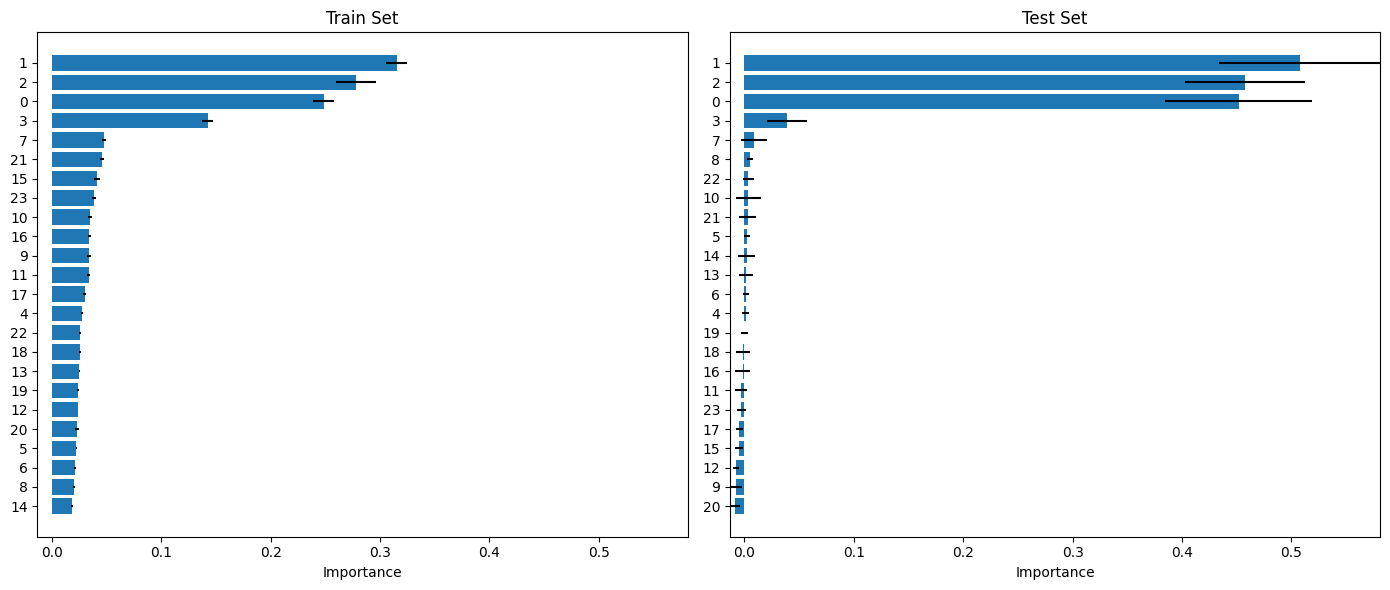

In [ ]:
n_features = X.shape[1]
feature_names = [f"{i}" for i in range(n_features)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

idx_train = np.argsort(rf_pi_train.importances_mean)
ax1.barh(
    range(n_features),
    rf_pi_train.importances_mean[idx_train],
    xerr=rf_pi_train.importances_std[idx_train],
)
ax1.set_yticks(range(n_features))
ax1.set_yticklabels(np.array(feature_names)[idx_train])
ax1.set_xlabel("Importance")
ax1.set_title("Train Set")

idx_test = np.argsort(rf_pi_test.importances_mean)
ax2.barh(
    range(n_features),
    rf_pi_test.importances_mean[idx_test],
    xerr=rf_pi_test.importances_std[idx_test],
)
ax2.set_yticks(range(n_features))
ax2.set_yticklabels(np.array(feature_names)[idx_test])
ax2.set_xlabel("Importance")
ax2.set_title("Test Set")

max_val = max(
    (rf_pi_train.importances_mean + rf_pi_train.importances_std).max(),
    (rf_pi_test.importances_mean + rf_pi_test.importances_std).max(),
)
min_val = min(
    0,
    (rf_pi_train.importances_mean - rf_pi_train.importances_std).min(),
    (rf_pi_test.importances_mean - rf_pi_test.importances_std).min(),
)
ax1.set_xlim([min_val, max_val])
ax2.set_xlim([min_val, max_val])

plt.tight_layout()
plt.show()

 The large difference between the importance computed on the train and test sets indicates
 that our model has overfitted on the train set. We also see it in the difference between
 the test and train $R^2$ scores.

 Observing that many features receive low importance on the test set, we can try to eliminate
 features to improve the quality of our model. Recursive Feature Elimination with Cross
 Validation (`RFECV`) provides a good way to trim down irrelevant features.
 [Justify that permutation importance is sensible by citing Reyero Lobo et al. ?]

In [ ]:
from sklearn.feature_selection import RFECV

# Extract validation data for permutation importance
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2)


def permutation_importance_getter(model, feature_indices, X_val, y_val, random_state):
    return permutation_importance(
        model,
        X_val[:, feature_indices],
        y_val,
        n_jobs=2,
        random_state=random_state,
    ).importances_mean


rfecv = RFECV(
    estimator=rf_regressor,
    cv=5,
    scoring="r2",
    min_features_to_select=1,
    importance_getter=lambda model, feature_indices: permutation_importance_getter(
        model, feature_indices, X_val, y_val, random_state=rng
    ),
)
rfecv.fit(X, y)

,estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance either through a ``coef_``attribute or through a ``feature_importances_`` attribute.,RandomForestR...x7F1F2E2AA340)
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.Note that the last iteration may remove fewer than ``step`` features inorder to reach ``min_features_to_select``.",1
,"min_features_to_select min_features_to_select: int, default=1The minimum number of features to be selected. This number of featureswill always be scored, even if the difference between the originalfeature count and ``min_features_to_select`` isn't divisible by``step``... versionadded:: 0.20",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If theestimator is not a classifier or if ``y`` is neither binary nor multiclass,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value of None changed from 3-fold to 5-fold.",5
,"scoring scoring: str or callable, default=NoneScoring method to evaluate the :class:`RFE` selectors' performance. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion ` is used.",'r2'
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"n_jobs n_jobs: int or None, default=NoneNumber of cores to run in parallel while fitting across folds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionadded:: 0.18",None
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance.For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case of:class:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature. When the callable also accepts`feature_indices` in its signature, it will be passed the index of the featuresof the full dataset that remain after elimination in previous iterations.`feature_indices` allows `RFE` to be used with permutation importance, asshown on `RFECV` at the end of:ref:`sphx_glr_auto_examples_feature_selection_plot_rfe_with_cross_validation.py`... versionadded:: 0.24.. versionchanged:: 1.8 Add support for passing `feature_indices` to the callable when part of its signature.",<function <la...x7f1fa41cc9a0>
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squar

 We see that once we trim the irrelevant features, our model performs much better on
 test data, with an $R^2$ score close to 1. This score does not drop significantly when
 we re-train on only half the data, indicating that the model is close to Bayes-optimal.
 This is also shown in the fact that permutation importance measures are very similar
 on the train and test sets.

 Looking at the features that were kept by `RFECV` and their permutation importance,
 we can see that features 0, 1 and 2 seem to be equally important for the underlying process.
 Interestingly, we see that feature 3 was also kept, while having relatively less
 importance. It was not obvious at first that this feature would be relevant for the
 underlying process, but we can now assert it as our model performs well.

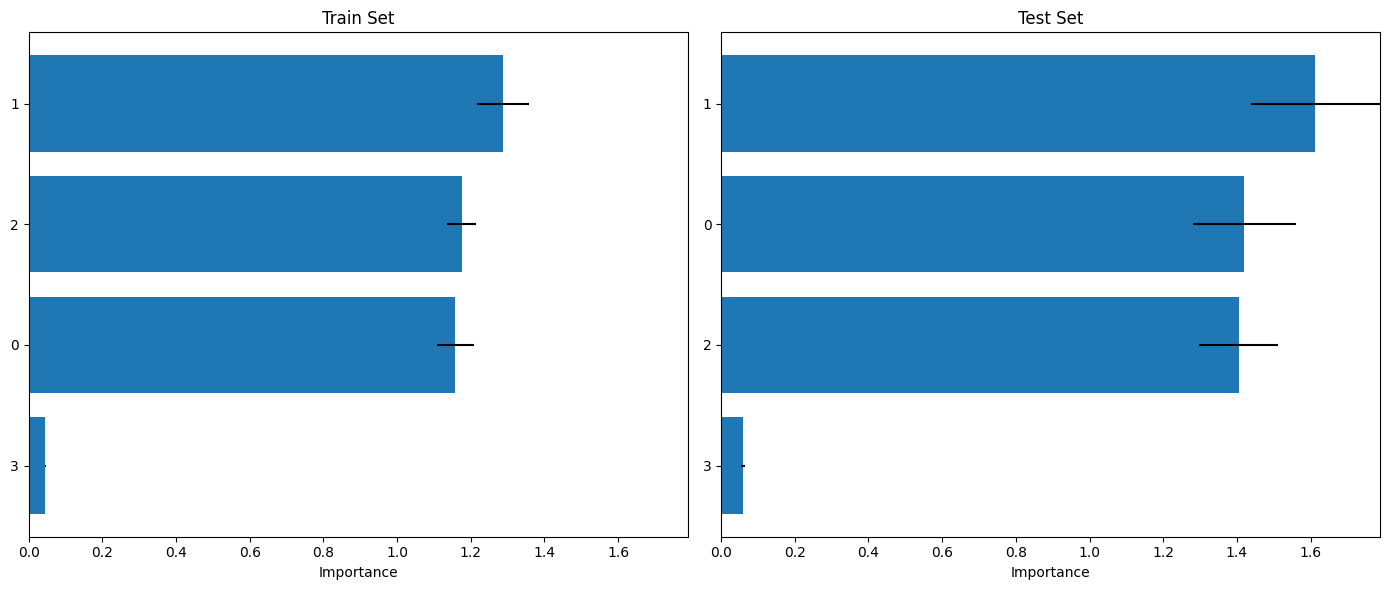

Test R^2 score of the trimmed model: 0.988
Test R^2 score of the trimmed model trained on half the data: 0.986


In [ ]:
n_features = sum(rfecv.support_)
feature_names = [f"{i}" for i in range(n_features) if rfecv.support_[i]]

rf_pi_train = permutation_importance(
    rfecv.estimator_, X_train[:, rfecv.support_], y_train, random_state=rng
)
rf_pi_test = permutation_importance(
    rfecv.estimator_, X_test[:, rfecv.support_], y_test, random_state=rng
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

idx_train = np.argsort(rf_pi_train.importances_mean)
ax1.barh(
    range(n_features),
    rf_pi_train.importances_mean[idx_train],
    xerr=rf_pi_train.importances_std[idx_train],
)
ax1.set_yticks(range(n_features))
ax1.set_yticklabels(np.array(feature_names)[idx_train])
ax1.set_xlabel("Importance")
ax1.set_title("Train Set")

idx_test = np.argsort(rf_pi_test.importances_mean)
ax2.barh(
    range(n_features),
    rf_pi_test.importances_mean[idx_test],
    xerr=rf_pi_test.importances_std[idx_test],
)
ax2.set_yticks(range(n_features))
ax2.set_yticklabels(np.array(feature_names)[idx_test])
ax2.set_xlabel("Importance")
ax2.set_title("Test Set")

max_val = max(
    (rf_pi_train.importances_mean + rf_pi_train.importances_std).max(),
    (rf_pi_test.importances_mean + rf_pi_test.importances_std).max(),
)
min_val = min(
    0,
    (rf_pi_train.importances_mean - rf_pi_train.importances_std).min(),
    (rf_pi_test.importances_mean - rf_pi_test.importances_std).min(),
)
ax1.set_xlim([min_val, max_val])
ax2.set_xlim([min_val, max_val])

plt.tight_layout()
plt.show()

print(
    f"Test R^2 score of the trimmed model: {rfecv.estimator_.score(X_test[:, rfecv.support_], y_test):.3f}"
)
# Refit the model on half the data
rfecv.estimator_.fit(
    X_train[: int(X_train.shape[0] / 2), rfecv.support_],
    y_train[: int(X_train.shape[0] / 2)],
)
print(
    f"Test R^2 score of the trimmed model trained on half the data: {rfecv.estimator_.score(X_test[:, rfecv.support_], y_test):.3f}"
)

 We showed here that we should be careful with feature importance: it can lead to misleading
 conclusions when the model is not optimal. We also showed how to use feature importance to
 perform feature selection and how that can lead to a better model.